In [1]:
# Environment Setup & Core Dependencies
# Import essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress warnings for clean execution output
warnings.filterwarnings('ignore')

# Pandas display configuration for analytical clarity
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# Set professional visualization styles
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

print("Dependencies loaded successfully.")

Dependencies loaded successfully.


In [2]:
# Load the primary dataset
df = pd.read_csv('Dataset.csv', sep='\t')

# Initial dataset inspection
print(f"Initial Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Missing Values Audit:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nFirst 3 Records:")
display(df.head(3))

Initial Dataset Dimensions: 2240 rows, 29 columns

Missing Values Audit:
Income    24
dtype: int64

First 3 Records:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.00,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.00,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.00,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0


In [3]:
# Handle missing values in 'Income' using median imputation to prevent outlier distortion
median_income = df['Income'].median()
df['Income'].fillna(median_income, inplace=True)

# Verify if any missing values remain
print(f"Remaining Missing Values: {df.isnull().sum().sum()}")
print(f"Cleaned Dataset Shape: {df.shape}")

Remaining Missing Values: 0
Cleaned Dataset Shape: (2240, 29)


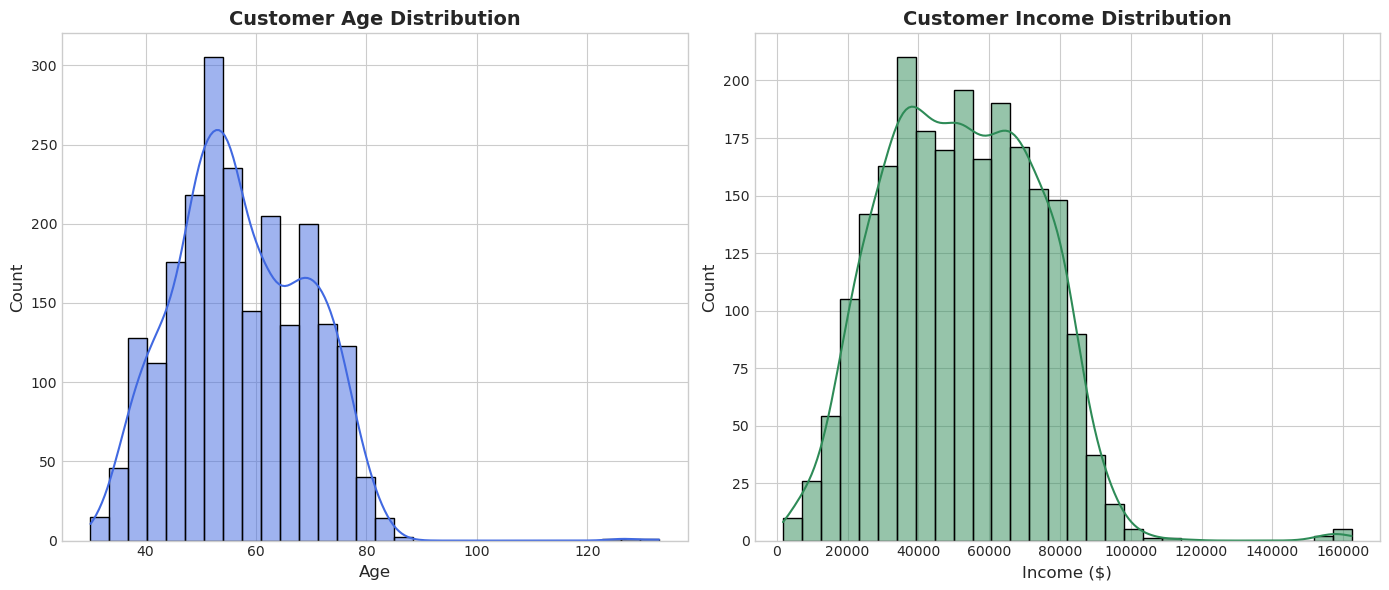

--- Age & Income Statistical Summary ---


,Age,Income
count,2240.00,2240.00
mean,57.19,52237.98
std,11.98,25037.96
min,30.00,1730.00
25%,49.00,35538.75
50%,56.00,51381.50
75%,67.00,68289.75
max,133.00,666666.00


In [4]:
# Exploratory Data Analysis: Customer Age Distribution and Income Analysis

# Calculate Age from 'Year_Birth' (Assuming current year is 2026 )
df['Age'] = 2026 - df['Year_Birth']

# Set up visualization figures
plt.figure(figsize=(14, 6))

# Plot 1: Customer Age Distribution
plt.subplot(1, 2, 1)
sns.histplot(df['Age'], bins=30, kde=True, color='royalblue')
plt.title('Customer Age Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Count', fontsize=12)

# Plot 2: Customer Income Distribution (Filtering out extreme outliers for clear visualization)
plt.subplot(1, 2, 2)
income_filtered = df[df['Income'] < 200000] # filtering out extreme income outliers for plotting
sns.histplot(income_filtered['Income'], bins=30, kde=True, color='seagreen')
plt.title('Customer Income Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Income ($)', fontsize=12)
plt.ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

# Display basic statistical summary for Age and Income
print("--- Age & Income Statistical Summary ---")
display(df[['Age', 'Income']].describe())

In [5]:
# Exporting the cleaned dataframe
output_file_path = 'cleaned_customer_data.csv'
df.to_csv(output_file_path, index=False)

print(f"Cleaned dataset successfully saved as '{output_file_path}'")
print(f"Final Saved Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")

Cleaned dataset successfully saved as 'cleaned_customer_data.csv'
Final Saved Dataset Shape: 2240 rows, 30 columns
